<a href="https://colab.research.google.com/github/attaboatengsr/data620/blob/main/project2_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
import pandas as pd
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import urllib.request
import zipfile
import ssl

In [8]:

url = "https://files.grouplens.org/datasets/movielens/ml-latest-small.zip"
zip_path = "ml-latest-small.zip"

# Create an unverified SSL context to bypass verification errors
context = ssl._create_unverified_context()

# Downloading the dataset using the unverified context
with urllib.request.urlopen(url, context=context) as response, open(zip_path, 'wb') as out_file:
    out_file.write(response.read())

# Extracting files
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(".")

In [10]:
# Load datasets
movies_df = pd.read_csv("ml-latest-small/movies.csv")
ratings_df = pd.read_csv("ml-latest-small/ratings.csv")

# Initialize Bipartite Graph
B = nx.Graph()

# Add nodes with bipartite attribute (0 = users, 1 = movies)
users = ratings_df['userId'].unique()
movies = ratings_df['movieId'].unique()

B.add_nodes_from(users, bipartite=0)
B.add_nodes_from(movies, bipartite=1)

# Add edges representing ratings
for _, row in ratings_df.iterrows():
    B.add_edge(row['userId'], row['movieId'], weight=row['rating'])

print(f"Bipartite Graph Loaded: {B.number_of_nodes()} total nodes ({len(users)} users, {len(movies)} movies)")

Bipartite Graph Loaded: 9811 total nodes (610 users, 9724 movies)


In [11]:
# Project onto Movie node set (Weights = number of shared users who rated both movies)
movie_nodes = [n for n, d in B.nodes(data=True) if d['bipartite'] == 1]
projected_graph = nx.bipartite.weighted_projected_graph(B, movie_nodes)

print(f"Original Projected Network: {projected_graph.number_of_nodes()} movies, {projected_graph.number_of_edges()} edges")

# Apply the Island Method: Filter edges using a strict weight threshold (e.g., >= 20 shared users)
# This removes weak co-rating noise and leaves behind core structural "islands"
island_threshold = 20
island_edges = [(u, v) for u, v, d in projected_graph.edges(data=True) if d['weight'] >= island_threshold]

# Construct the reduced island graph
island_graph = nx.Graph()
island_graph.add_edges_from(island_edges)

# Remove isolated nodes (movies with no remaining connections above threshold)
island_graph.remove_nodes_from(list(nx.isolates(island_graph)))

print(f"Reduced Island Network: {island_graph.number_of_nodes()} movies, {island_graph.number_of_edges()} edges")

Original Projected Network: 9811 movies, 13944872 edges
Reduced Island Network: 1608 movies, 177198 edges


Final Render Graph: 25 nodes, 297 edges


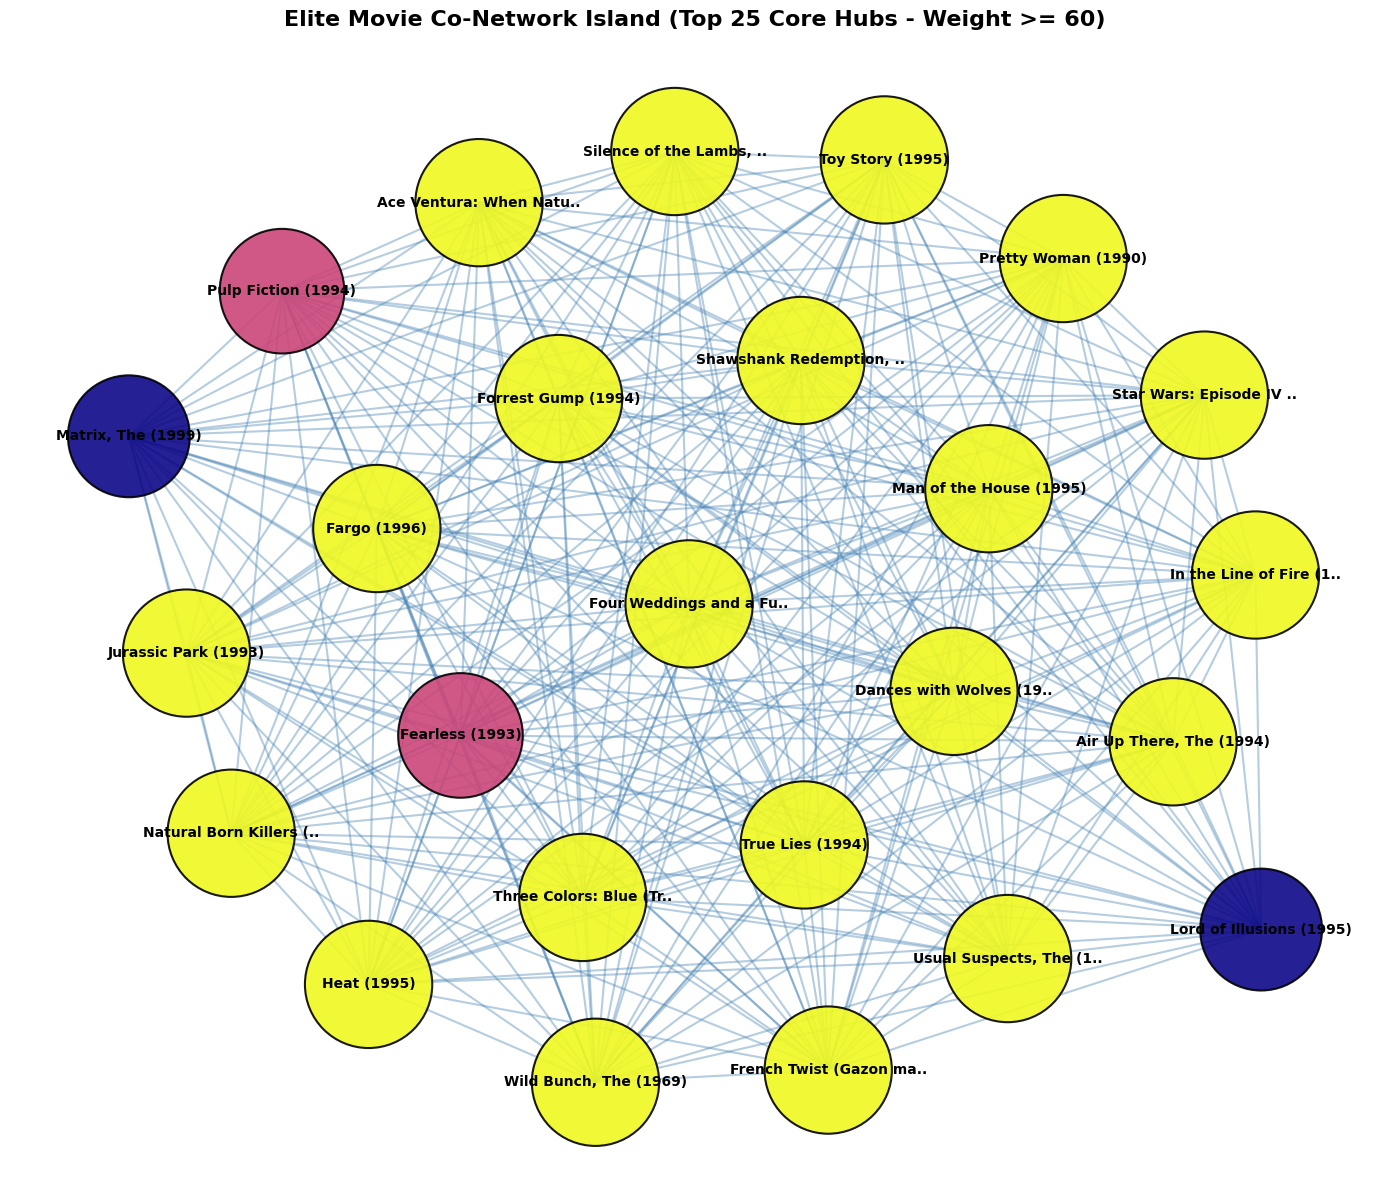

In [14]:
plt.figure(figsize=(14, 12))

# 1. Use the projected graph and filter for a very high weight threshold (e.g., >= 60 shared users)
high_weight_threshold = 60
edges_filtered = [(u, v) for u, v, d in projected_graph.edges(data=True) if d['weight'] >= high_weight_threshold]

G_clean = nx.Graph()
G_clean.add_edges_from(edges_filtered)

# 2. To ensure zero clutter, take only the top 25 most central nodes in this clean graph
if len(G_clean) > 0:
    centrality_dict = nx.degree_centrality(G_clean)
    top_nodes = sorted(centrality_dict, key=centrality_dict.get, reverse=True)[:25]
    final_subgraph = G_clean.subgraph(top_nodes).copy()
else:
    final_subgraph = G_clean

print(f"Final Render Graph: {final_subgraph.number_of_nodes()} nodes, {final_subgraph.number_of_edges()} edges")

# 3. Use a wide spring layout with high repulsion ('k=1.2') to spread nodes apart
pos = nx.spring_layout(final_subgraph, k=1.2, iterations=200, seed=42)

# 4. Scale node sizes and colors cleanly
sub_degrees = dict(final_subgraph.degree())
node_sizes = [v * 350 for v in sub_degrees.values()]
node_colors = [nx.degree_centrality(final_subgraph)[node] for node in final_subgraph.nodes()]

# 5. Draw graph components
nx.draw_networkx_edges(final_subgraph, pos, width=1.5, alpha=0.4, edge_color='steelblue')
nx.draw_networkx_nodes(
    final_subgraph, pos,
    node_size=node_sizes,
    node_color=node_colors,
    cmap=plt.cm.plasma,
    alpha=0.9,
    edgecolors='black',
    linewidths=1.5
)

# 6. Map node IDs to full/short movie titles safely
id_to_title = dict(zip(movies_df['movieId'], movies_df['title']))
labels = {node: id_to_title.get(node, str(node)) for node in final_subgraph.nodes()}
# Slight shortening for perfection
short_labels = {k: (v[:22] + '..') if len(v) > 24 else v for k, v in labels.items()}

nx.draw_networkx_labels(
    final_subgraph, pos,
    labels=short_labels,
    font_size=10,
    font_weight='bold',
    font_family='sans-serif'
)

plt.title('Elite Movie Co-Network Island (Top 25 Core Hubs - Weight >= 60)', fontsize=16, fontweight='bold', pad=20)
plt.axis('off')
plt.tight_layout()
plt.show()

Movies with higher degree centrality shared viewers across a massive portion of the other films in the dataset.

Certain genres (such as Crime, Thriller, and Drama) share fluid audience overlaps, while strictly siloed genre content fades away under stricter weight thresholds, indicating specialized or isolated viewer demographics.